In [1]:
import sys
sys.path.append("../src")   # notebooks run from notebooks/, so ../src finds our modules

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from data_access import load_sales_enriched

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [2]:
df = load_sales_enriched()

print("Shape:", df.shape)
print("Revenue total:", round(df["revenue_usd"].sum(), 2))
print("Order date range:", df["order_date"].min().date(), "to", df["order_date"].max().date())
print("Missing delivery dates:", df["delivery_date"].isna().sum())
df.dtypes

Shape: (62884, 31)
Revenue total: 55755479.59
Order date range: 2016-01-01 to 2021-02-20
Missing delivery dates: 49719


order_number                  int64
line_item                     int64
order_date            datetime64[s]
delivery_date         datetime64[s]
delivery_days               float64
year                          int64
quarter                       int64
month                         int64
month_name                      str
month_start           datetime64[s]
customer_key                  int64
gender                          str
customer_country                str
customer_continent              str
store_key                     int64
channel                         str
store_country                   str
product_key                   int64
product_name                    str
brand                           str
category                        str
subcategory                     str
quantity                      int64
currency_code                   str
unit_price_usd              float64
unit_cost_usd               float64
revenue_usd                 float64
cost_usd                    

In [3]:
monthly = (
    df.groupby("month_start")
      .agg(revenue=("revenue_usd", "sum"),
           profit=("profit_usd", "sum"),
           orders=("order_number", "nunique"),
           active_days=("order_date", "nunique"))
      .reset_index()
)
monthly = monthly[monthly["month_start"] < "2021-02-01"].copy()   # drop partial Feb 2021
monthly["revenue_12m_avg"] = monthly["revenue"].rolling(12).mean()

print(len(monthly), "months")
print("Last 12-month sum:", round(monthly["revenue"].tail(12).sum(), 0))
monthly.head(3)

61 months
Last 12-month sum: 7738703.0


,month_start,revenue,profit,orders,active_days,revenue_12m_avg
0,2016-01-01,"649,918.78","388,268.96",292,28,NaN
1,2016-02-01,"891,098.30","531,722.75",334,28,NaN
2,2016-03-01,"338,407.36","203,506.99",109,15,NaN


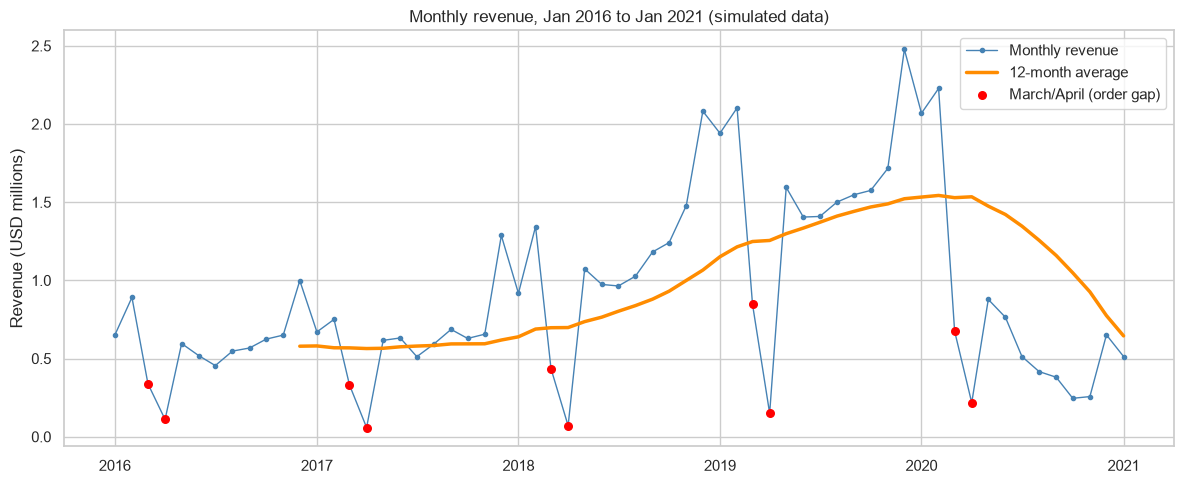

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["month_start"], monthly["revenue"] / 1e6,
        marker="o", markersize=3, linewidth=1, color="steelblue", label="Monthly revenue")
ax.plot(monthly["month_start"], monthly["revenue_12m_avg"] / 1e6,
        linewidth=2.5, color="darkorange", label="12-month average")

# Mark March and April, where the annual order gap makes totals unreliable
gap = monthly[monthly["month_start"].dt.month.isin([3, 4])]
ax.scatter(gap["month_start"], gap["revenue"] / 1e6,
           color="red", s=30, zorder=3, label="March/April (order gap)")

ax.set_title("Monthly revenue, Jan 2016 to Jan 2021 (simulated data)")
ax.set_ylabel("Revenue (USD millions)")
ax.set_xlabel("")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/monthly_revenue.png", dpi=150)
plt.show()

           revenue        profit  growth_pct
year                                        
2016  6,946,793.60  4,107,000.50         NaN
2017  7,421,422.30  4,337,064.10        6.80
2018 12,788,960.70  7,464,961.10       72.30
2019 18,264,382.50 10,697,738.90       42.80
2020  9,294,632.10  5,447,460.10      -49.10


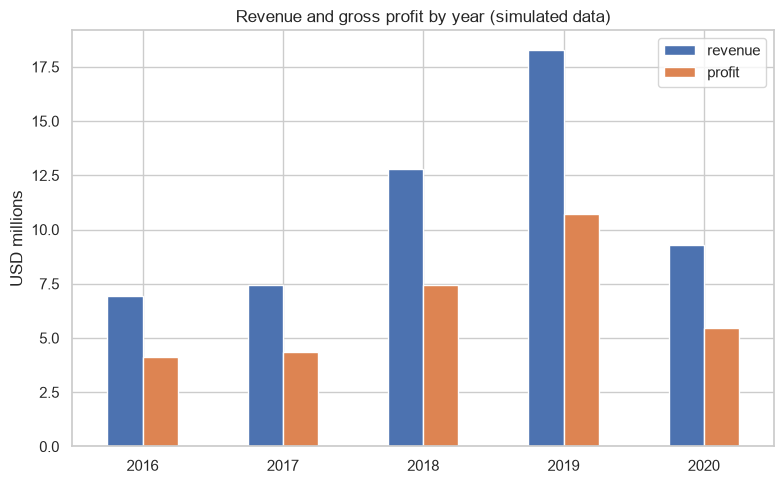

In [5]:
yearly = (
    df[df["year"] <= 2020]               # full years only
      .groupby("year")
      .agg(revenue=("revenue_usd", "sum"), profit=("profit_usd", "sum"))
)
yearly["growth_pct"] = yearly["revenue"].pct_change() * 100
print(yearly.round(1))

ax = (yearly[["revenue", "profit"]] / 1e6).plot(kind="bar", figsize=(8, 5), rot=0)
ax.set_title("Revenue and gross profit by year (simulated data)")
ax.set_ylabel("USD millions")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("../reports/figures/yearly_revenue_profit.png", dpi=150)
plt.show()
